<a href="https://colab.research.google.com/github/dimonkOHYRY111/pattern-recognition-practice/blob/classification-mini-project/PR04_Kochura_Dmytro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота №4
## Підготовка даних, Pipeline і логістична регресія

**Дисципліна:** Розпізнавання образів і машинне навчання

**Студент:** Кочура Д.С.

**Група:** ІН-32.

**Дата виконання:** 08.11.2026

### Мета роботи

Навчитися готувати дані, створювати Pipeline, досліджувати логістичну регресію та оцінювати моделі за допомогою крос-валідації.

In [1]:

!pip -q install ucimlrepo

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from google.colab import drive
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_validate, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression


In [2]:

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/patternrecognition-practice"
)

MINI_DIR = PROJECT_DIR / "classification-mini-project"
DATA_DIR = MINI_DIR / "data"
NOTEBOOKS_DIR = MINI_DIR / "notebooks"
MODELS_DIR = MINI_DIR / "models"
REPORTS_DIR = MINI_DIR / "reports"

for folder in [DATA_DIR, NOTEBOOKS_DIR, MODELS_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "heart_disease.csv"

print("Папка проєкту:", MINI_DIR)
print("Папка даних:", DATA_DIR)


Mounted at /content/drive
Папка проєкту: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project
Папка даних: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project/data


In [3]:

if DATA_PATH.exists():
    data = pd.read_csv(DATA_PATH)
    print("Дані завантажено з CSV.")
else:
    heart = fetch_ucirepo(id=45)

    data = heart.data.features.copy()
    original_target = heart.data.targets["num"]

    # Перетворення на бінарну класифікацію
    data["target"] = (original_target > 0).astype(int)

    data.to_csv(DATA_PATH, index=False)
    print("Файл heart_disease.csv створено.")

display(data.head())
print("Розмір:", data.shape)
print("Файл:", DATA_PATH)


Файл heart_disease.csv створено.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Розмір: (303, 14)
Файл: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project/data/heart_disease.csv


## 1. Первинний аналіз даних

На цьому етапі перевіряється структура набору даних, типи ознак, пропущені значення та розподіл класів.

In [4]:

print("Розмір таблиці:", data.shape)

print("\nТипи даних:")
print(data.dtypes)

print("\nПропущені значення:")
print(data.isna().sum())

print("\nРозподіл класів:")
print(data["target"].value_counts().sort_index())

print("\nУнікальні класи:")
print(data["target"].unique())

display(data.head(10))


Розмір таблиці: (303, 14)

Типи даних:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object

Пропущені значення:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Розподіл класів:
target
0    164
1    139
Name: count, dtype: int64

Унікальні класи:
[0 1]


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0.0,3.0,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2.0,3.0,1
7,57,0,4,120,354,0,0,163,1,0.6,1,0.0,3.0,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1.0,7.0,1
9,53,1,4,140,203,1,2,155,1,3.1,3,0.0,7.0,1


In [5]:

numeric_columns = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_columns = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

print("Числові ознаки:", numeric_columns)
print("Категоріальні ознаки:", categorical_columns)
print("Цільова змінна: target")

assert set(numeric_columns + categorical_columns + ["target"]) == set(data.columns)
assert set(data["target"].dropna().unique()) == {0, 1}


Числові ознаки: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Категоріальні ознаки: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Цільова змінна: target


In [6]:

audit = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів",
        "Кількість вхідних ознак",
        "Кількість числових ознак",
        "Кількість категоріальних ознак",
        "Кількість пропусків",
        "Кількість класів",
        "Позитивний клас"
    ],
    "Значення": [
        len(data),
        data.shape[1] - 1,
        len(numeric_columns),
        len(categorical_columns),
        data.isna().sum().sum(),
        data["target"].nunique(),
        1
    ]
})

display(audit)


,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Кількість числових ознак,5
3,Кількість категоріальних ознак,8
4,Кількість пропусків,6
5,Кількість класів,2
6,Позитивний клас,1


## 2. Розділення даних

Дані поділяються на 80% навчальної та 20% тестової вибірки. Тестова вибірка не використовується для вибору моделі.

In [7]:

X = data.drop(columns=["target"])
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nЧастки класів train:")
print(y_train.value_counts(normalize=True).round(3))

print("\nЧастки класів test:")
print(y_test.value_counts(normalize=True).round(3))


X_train: (242, 13)
X_test: (61, 13)

Частки класів train:
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Частки класів test:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [8]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc"
}


In [9]:

def make_pipeline(scale=True):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale else "passthrough")
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            solver="liblinear",
            random_state=42
        ))
    ])


## 3. Вплив масштабування

Порівнюються дві логістичні регресії: зі стандартизацією числових ознак та без неї. Оцінювання виконується за однаковою крос-валідацією.

In [10]:

scale_results = []

for scale in [False, True]:
    model = make_pipeline(scale=scale)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    model.fit(X_train, y_train)

    scale_results.append({
        "scaling": "StandardScaler" if scale else "Без масштабування",
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "CV_ROC_AUC_std": scores["test_roc_auc"].std(),
        "iterations": model.named_steps["classifier"].n_iter_.max()
    })

scale_df = pd.DataFrame(scale_results)
display(scale_df.round(3))


,scaling,CV_F1,CV_F1_std,CV_ROC_AUC,CV_ROC_AUC_std,iterations
0,Без масштабування,0.825,0.007,0.902,0.015,13
1,StandardScaler,0.825,0.007,0.902,0.014,6


## 4. Підбір гіперпараметрів

Досліджується вплив L1- та L2-регуляризації і параметра C. Найкраща конфігурація обирається за середнім CV F1 без використання тестової вибірки.

In [11]:

model = make_pipeline(scale=True)

param_grid = {
    "preprocessor__num__scaler": [
        StandardScaler(), "passthrough"
    ],
    "classifier__penalty": ["l1", "l2"],
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

grid.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid.best_params_)

print("\nНайкраща CV F1:")
print(round(grid.best_score_, 3))


Найкращі параметри:
{'classifier__C': 10, 'classifier__penalty': 'l2', 'preprocessor__num__scaler': StandardScaler()}

Найкраща CV F1:
0.836


In [12]:

results_df = pd.DataFrame(grid.cv_results_)

comparison = results_df[[
    "param_preprocessor__num__scaler",
    "param_classifier__penalty",
    "param_classifier__C",
    "mean_test_f1",
    "std_test_f1",
    "mean_test_roc_auc",
    "std_test_roc_auc"
]].copy()

comparison.columns = [
    "Scaling", "Penalty", "C",
    "CV_F1", "CV_F1_std",
    "CV_ROC_AUC", "CV_ROC_AUC_std"
]

comparison["Scaling"] = comparison["Scaling"].apply(
    lambda x: "Без масштабування"
    if x == "passthrough" else "StandardScaler"
)

comparison = comparison.sort_values(
    "CV_F1", ascending=False
)

display(comparison.round(3))


,Scaling,Penalty,C,CV_F1,CV_F1_std,CV_ROC_AUC,CV_ROC_AUC_std
19,Без масштабування,l2,100.00,0.836,0.013,0.898,0.012
14,StandardScaler,l2,10.00,0.836,0.013,0.900,0.013
18,StandardScaler,l2,100.00,0.836,0.013,0.898,0.012
16,StandardScaler,l1,100.00,0.836,0.013,0.897,0.012
15,Без масштабування,l2,10.00,0.836,0.013,0.902,0.012
17,Без масштабування,l1,100.00,0.832,0.011,0.897,0.012
13,Без масштабування,l1,10.00,0.832,0.011,0.902,0.011
12,StandardScaler,l1,10.00,0.832,0.011,0.902,0.010
11,Без масштабування,l2,1.00,0.825,0.007,0.902,0.015
10,StandardScaler,l2,1.00,0.825,0.007,0.902,0.014


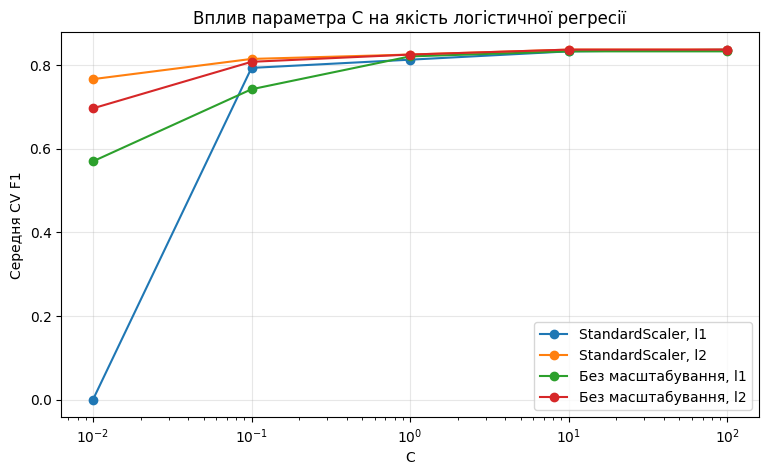

In [13]:

plt.figure(figsize=(9, 5))

for (scaling, penalty), group in comparison.groupby(
    ["Scaling", "Penalty"]
):
    group = group.sort_values("C")

    plt.plot(
        group["C"].astype(float),
        group["CV_F1"],
        marker="o",
        label=f"{scaling}, {penalty}"
    )

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Середня CV F1")
plt.title("Вплив параметра C на якість логістичної регресії")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [14]:

best_model = grid.best_estimator_

feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = best_model.named_steps[
    "classifier"
].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefficients,
    "Модуль": abs(coefficients)
})

top_5 = coef_df.sort_values(
    "Модуль", ascending=False
).head(5)

display(top_5.round(3))


,Ознака,Коефіцієнт,Модуль
21,cat__ca_0.0,-1.926,1.926
10,cat__cp_4.0,1.189,1.189
27,cat__thal_7.0,0.978,0.978
7,cat__cp_1.0,-0.892,0.892
5,cat__sex_0.0,-0.880,0.880


## 5. Аналіз коефіцієнтів

Додатні коефіцієнти збільшують прогнозовані log-odds позитивного класу, а від’ємні — зменшують. Більший модуль означає сильніший вплив на лінійний прогноз за інших рівних умов. Це не доводить причинного зв’язку.

## Висновки до практичної роботи №4

Під час роботи підготовлено набір Heart Disease, створено Pipeline та досліджено логістичну регресію.

Проведено порівняння моделей зі стандартизацією та без неї, а також L1- і L2-регуляризації для різних значень C.

Найкращу конфігурацію обрано за результатами крос-валідації на навчальній вибірці. Тестові дані не використовувалися.